<a href="https://colab.research.google.com/github/dikshasable120/Machine-learning-ML-/blob/main/K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## K Means Clustering

In [1]:
path = r"https://raw.githubusercontent.com/dikshasable120/Datasets/refs/heads/main/Mall_Customers.csv"
import  pandas as pd
df = pd.read_csv(path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Perform basic data qualty checks

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
# missing data
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [4]:
# duplicates
df.duplicated().sum()

np.int64(0)

In [5]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

## Consider features required for X (Cluster formation)
X: age,income and spending

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [7]:
X.columns = ['Age','Income','Spending']
X.head()

,Age,Income,Spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [8]:
num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
).set_output(transform='pandas')

num_pipe

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [9]:
X_pre = num_pipe.fit_transform(X)
X_pre.head()


,Age,Income,Spending
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## K Means CLuster

In [10]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=4)
model.fit(X_pre)

KMeans(n_clusters=4)

In [11]:
clusters4 = model.predict(X_pre)
clusters4

array([3, 3, 3, 3, 3, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 3, 3, 0, 3, 3, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3,
       0, 3, 0, 3, 3, 3, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 0, 3,
       0, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 3, 0, 0, 3, 0, 0, 3,
       3, 0, 0, 3, 0, 0, 3, 3, 0, 3, 0, 3, 3, 0, 0, 3, 0, 3, 0, 0, 0, 0,
       0, 3, 2, 3, 3, 3, 0, 0, 0, 0, 3, 2, 1, 1, 2, 1, 2, 1, 0, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

## Evaluation Metric: Inertia

In [12]:
model.inertia_

205.22514747675913

## Choosing the best cluster with the help of Elbow method

In [13]:
pip install yellowbrick

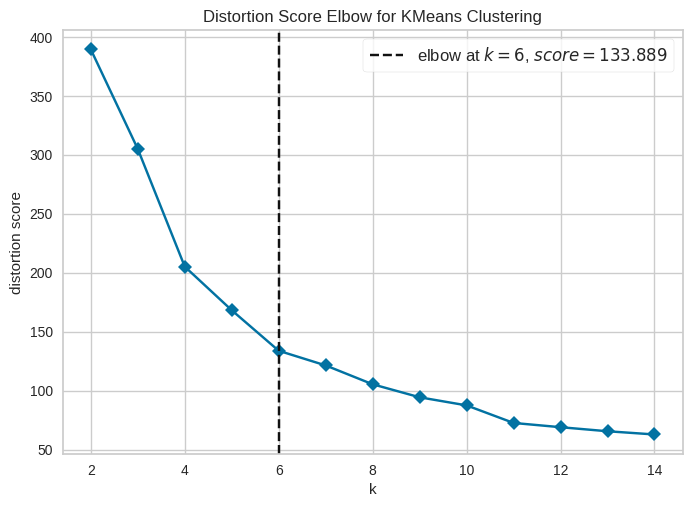

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [14]:
from yellowbrick.cluster import kelbow_visualizer
base_model = KMeans()
visualizer = kelbow_visualizer(base_model,X_pre,k=(2,15),timings=False)
visualizer.show()

## The value of k from the eblow method is 7.

## Rebuild the model with number of clusters as 7

In [15]:
final_model = KMeans(n_clusters=7)
final_model.fit(X_pre)

KMeans(n_clusters=7)

In [16]:
labels = final_model.predict(X_pre)
labels

array([4, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 6, 1, 2, 4,
       2, 1, 6, 4, 4, 4, 6, 4, 4, 6, 6, 6, 6, 6, 4, 6, 6, 4, 6, 6, 6, 4,
       6, 6, 4, 4, 6, 6, 6, 6, 6, 4, 6, 4, 4, 6, 6, 4, 6, 6, 4, 6, 6, 4,
       4, 6, 6, 4, 6, 4, 4, 4, 6, 4, 6, 4, 4, 6, 6, 4, 6, 4, 6, 6, 6, 6,
       6, 4, 4, 4, 4, 4, 6, 6, 6, 6, 4, 4, 5, 5, 4, 5, 0, 5, 0, 5, 0, 5,
       4, 5, 0, 5, 0, 5, 0, 5, 0, 5, 4, 5, 0, 5, 0, 5, 0, 5, 0, 5, 0, 5,
       0, 5, 0, 5, 0, 5, 6, 5, 0, 5, 0, 5, 0, 5, 0, 5, 0, 5, 0, 5, 0, 5,
       0, 5, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3,
       0, 3], dtype=int32)

 ## Add this labels list to the dataframe and share it with the client

In [17]:
df['Cluster Number'] = labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,4
1,2,Male,21,15,81,1
2,3,Female,20,16,6,2
3,4,Female,23,16,77,1
4,5,Female,31,17,40,2


In [18]:
df[df['Cluster Number']==3]


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
179,180,Male,35,93,90,3
181,182,Female,32,97,86,3
183,184,Female,29,98,88,3
185,186,Male,30,99,97,3
187,188,Male,28,101,68,3
189,190,Female,36,103,85,3
191,192,Female,32,103,69,3
193,194,Female,38,113,91,3
195,196,Female,35,120,79,3
197,198,Male,32,126,74,3


In [19]:
print("Customer groups")

for i in range(5):
  display(df[df['Cluster Number']==i])

Customer groups


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
126,127,Male,43,71,35,0
128,129,Male,59,71,11,0
130,131,Male,47,71,9,0
134,135,Male,20,73,5,0
136,137,Female,44,73,7,0
138,139,Male,19,74,10,0
140,141,Female,57,75,5,0
144,145,Male,25,77,12,0
146,147,Male,48,77,36,0
148,149,Female,34,78,22,0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
1,2,Male,21,15,81,1
3,4,Female,23,16,77,1
5,6,Female,22,17,76,1
7,8,Female,23,18,94,1
9,10,Female,30,19,72,1
11,12,Female,35,19,99,1
13,14,Female,24,20,77,1
15,16,Male,22,20,79,1
17,18,Male,20,21,66,1
19,20,Female,35,23,98,1


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
2,3,Female,20,16,6,2
4,5,Female,31,17,40,2
6,7,Female,35,18,6,2
8,9,Male,64,19,3,2
10,11,Male,67,19,14,2
12,13,Female,58,20,15,2
14,15,Male,37,20,13,2
16,17,Female,35,21,35,2
18,19,Male,52,23,29,2
20,21,Male,35,24,35,2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
179,180,Male,35,93,90,3
181,182,Female,32,97,86,3
183,184,Female,29,98,88,3
185,186,Male,30,99,97,3
187,188,Male,28,101,68,3
189,190,Female,36,103,85,3
191,192,Female,32,103,69,3
193,194,Female,38,113,91,3
195,196,Female,35,120,79,3
197,198,Male,32,126,74,3


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,4
43,44,Female,31,39,61,4
47,48,Female,27,40,47,4
48,49,Female,29,40,42,4
49,50,Female,31,40,42,4
51,52,Male,33,42,60,4
52,53,Female,31,43,54,4
58,59,Female,27,46,51,4
61,62,Male,19,46,55,4
65,66,Male,18,48,59,4


In [20]:
df.to_csv("ClusterResults.csv",index=False)